# **Exploratory Data Analysis EDA**

This notebook is dedicated to performing Exploratory Data Analysis (EDA) on the raw data of the Tanzania Tourism project.



## Main Objectives of the Analysis

- Understand the basic structure of the dataset.
- Identify the data types of each column, such as numerical and categorical data.
- Examine missing values and determine the most appropriate strategy for handling them based on their characteristics.
- Analyze data distributions and tails.
- Explore the relationships between the target variable and the other features.
- Identify data quality issues.
- Prepare the data for the data preprocessing and machine learning stages.

## 1. Import Required Libraries

The following libraries are used throughout the analysis:

- `Path` for handling file and directory paths in a platform-independent way.
- `sys` for interacting with Python's runtime environment and modifying the module search path.
- `NumPy` for numerical operations.
- `Pandas` for data manipulation and analysis.
- `Matplotlib` and `Seaborn` for visualization.
- `MaxNLocator` for controlling the number of ticks in plots.


In [ ]:
import sys
from pathlib import Path

notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import src.config as cfg
import importlib
importlib.reload(cfg)

from src.config import (
    TRAIN_DATA_PATH,
    TARGET_COL,
    TARGET_CLASSES,
    NUMERIC_COLS,
    CATEGORICAL_COLS,
    VARIABLE_DEFINITIONS_PATH
)

import numpy as np, pandas as pd,  matplotlib.pyplot as plt, seaborn as sns
from dython.nominal import associations


## 2. Load Data

In [290]:
df = pd.read_csv(TRAIN_DATA_PATH)
vb_df = pd.read_csv(VARIABLE_DEFINITIONS_PATH)


In [292]:
df

,Tour_ID,country,age_group,travel_with,total_female,total_male,purpose,main_activity,info_source,tour_arrangement,...,package_accomodation,package_food,package_transport_tz,package_sightseeing,package_guided_tour,package_insurance,night_mainland,night_zanzibar,first_trip_tz,cost_category
0,tour_id1hffseyw,ITALY,45-64,With Children,0.0,2.0,Visiting Friends and Relatives,Beach Tourism,"Friends, relatives",Package Tour,...,Yes,Yes,Yes,No,No,No,0,7,Yes,High Cost
1,tour_idnacd7zag,UNITED KINGDOM,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Wildlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,No,No,No,0,7,Yes,High Cost
2,tour_id62vz7e71,UNITED STATES OF AMERICA,65+,With Spouse,1.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,Yes,Yes,No,6,6,Yes,Higher Cost
3,tour_idrc76tzix,RWANDA,25-44,With Spouse and Children,3.0,1.0,Leisure and Holidays,Beach Tourism,"Radio, TV, Web",Independent,...,No,No,No,No,No,No,3,0,No,Lower Cost
4,tour_idn723m0n9,UNITED STATES OF AMERICA,45-64,Alone,0.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,No,Yes,Yes,7,0,Yes,Higher Cost
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18501,tour_idmp5ciw50,KENYA,45-64,Alone,0.0,1.0,Other,Hunting Tourism,Others,Independent,...,No,No,No,No,No,No,3,0,No,Lower Cost
18502,tour_ideq0yncfs,KENYA,45-64,Alone,1.0,0.0,Meetings and Conference,Wildlife Tourism,Others,Independent,...,No,No,No,No,No,No,2,0,No,Lower Cost
18503,tour_idv7pz3vs8,UNITED STATES OF AMERICA,25-44,With Spouse and Children,2.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Independent,...,No,No,No,No,No,No,9,0,Yes,Higher Cost
18504,tour_idy6ydo00w,UNITED STATES OF AMERICA,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Conference Tourism,"Radio, TV, Web",Package Tour,...,Yes,Yes,Yes,Yes,Yes,No,13,4,No,Higher Cost


In [293]:
vb_df

,Column Name,Definition
0,id,Unique identifier for each tourist
1,country,The country a tourist coming from.
2,age_group,The age group of a tourist.
3,travel_with,The relation of people a tourist travel with t...
4,total_female,Total number of females
5,total_male,Total number of males
6,purpose,The purpose of visiting Tanzania
7,main_activity,The main activity of tourism in Tanzania
8,infor_source,The source of information about tourism in Tan...
9,tour_arrangment,The arrangment of visiting Tanzania


## 3. Initial Dataset Inspection

Before performing any cleaning or statistical analysis, we first inspect the basic structure of the dataset.

The following checks will help us understand:

- Number of observations and features.
- Data types.
- Missing values.
- Unique values.
- Basic statistical properties.

In [4]:
print('Number of observations is', df.shape[0], 'and number of features is', df.shape[1])

Number of observations is 18506 and number of features is 21


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18506 entries, 0 to 18505
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Tour_ID                18506 non-null  object 
 1   country                18506 non-null  object 
 2   age_group              18506 non-null  object 
 3   travel_with            17431 non-null  object 
 4   total_female           18504 non-null  float64
 5   total_male             18500 non-null  float64
 6   purpose                18506 non-null  object 
 7   main_activity          18506 non-null  object 
 8   info_source            18506 non-null  object 
 9   tour_arrangement       18506 non-null  object 
 10  package_transport_int  18506 non-null  object 
 11  package_accomodation   18506 non-null  object 
 12  package_food           18506 non-null  object 
 13  package_transport_tz   18506 non-null  object 
 14  package_sightseeing    18506 non-null  object 
 15  pa

In [6]:
print("Number of missing values in each column:")
print(df.isna().sum().replace(0, ""))

Number of missing values in each column:
Tour_ID                      
country                      
age_group                    
travel_with              1075
total_female                2
total_male                  6
purpose                      
main_activity                
info_source                  
tour_arrangement             
package_transport_int        
package_accomodation         
package_food                 
package_transport_tz         
package_sightseeing          
package_guided_tour          
package_insurance            
night_mainland               
night_zanzibar               
first_trip_tz                
cost_category                
dtype: object


In [ ]:
for col in df.columns:
    print(df[col].name,'\n', df[col].unique(), '\n')

Tour_ID 
 ['tour_id1hffseyw' 'tour_idnacd7zag' 'tour_id62vz7e71' ...
 'tour_idv7pz3vs8' 'tour_idy6ydo00w' 'tour_idceoq9por'] 

country 
 ['ITALY' 'UNITED KINGDOM' 'UNITED STATES OF AMERICA' 'RWANDA' 'FRANCE'
 'SWIZERLAND' 'NIGERIA' 'AUSTRALIA' 'SPAIN' 'DENMARK' 'BELGIUM' 'ZAMBIA'
 'NETHERLANDS' 'CANADA' 'INDIA' 'NORWAY' 'ZIMBABWE' 'MORROCO' 'CHINA'
 'GERMANY' 'SOUTH AFRICA' 'JAPAN' 'UAE' 'RUSSIA' 'KENYA' 'GREECE' 'POLAND'
 'AUSTRIA' 'MALAYSIA' 'CZECH REPUBLIC' 'KOREA' 'DRC' 'CYPRUS' 'KUWAIT'
 'BRAZIL' 'CHILE' 'BULGARIA' 'UNITED ARAB EMIRATES' 'ISRAEL' 'NEW ZEALAND'
 'UGANDA' 'IRELAND' 'SWEDEN' 'QATAR' 'CONGO' 'BURUNDI' 'FINLAND' 'GHANA'
 'OMAN' 'LEBANON' 'LUXEMBOURG' 'IVORY COAST' 'NAMIBIA' 'ROMANIA'
 'THAILAND' 'SUDAN' 'SINGAPORE' 'PORTUGAL' 'MALAWI' 'MALT' 'EGYPT'
 'PAKISTAN' 'TANZANIA' 'ARGENTINA' 'SRI LANKA' 'BOTSWANA' 'VIETNAM'
 'BERMUDA' 'TAIWAN' 'SENEGAL' 'AFGHANISTAN' 'COLOMBIA' 'JAMAICA' 'BAHRAIN'
 'COSTARICA' 'COMORO' 'URUGUAY' 'SAUD ARABIA' 'ETHIOPIA' 'PHILIPINES'
 'ARMENIA'

In [8]:
df.describe(include='all')

,Tour_ID,country,age_group,travel_with,total_female,total_male,purpose,main_activity,info_source,tour_arrangement,...,package_accomodation,package_food,package_transport_tz,package_sightseeing,package_guided_tour,package_insurance,night_mainland,night_zanzibar,first_trip_tz,cost_category
count,18506,18506,18506,17431,18504.000000,18500.000000,18506,18506,18506,18506,...,18506,18506,18506,18506,18506,18506,18506.000000,18506.000000,18506,18506
unique,18506,131,5,5,NaN,NaN,8,10,8,2,...,2,2,2,2,2,2,NaN,NaN,2,6
top,tour_id1hffseyw,UNITED STATES OF AMERICA,25-44,Alone,NaN,NaN,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,No,No,No,No,No,No,NaN,NaN,Yes,Normal Cost
freq,1,2846,9047,7590,NaN,NaN,11755,5988,8005,9295,...,9541,10143,10873,12786,12447,15809,NaN,NaN,12737,5471
mean,NaN,NaN,NaN,NaN,0.936230,0.998757,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,9.141576,2.493516,NaN,NaN
std,NaN,NaN,NaN,NaN,1.215582,1.173177,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,14.127449,5.275156,NaN,NaN
min,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,0.000000,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,0.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,11.000000,4.000000,NaN,NaN


In [9]:
print(f'Duplicated row : {df.duplicated().sum()}')

Duplicated row : 0


In [10]:
df

,Tour_ID,country,age_group,travel_with,total_female,total_male,purpose,main_activity,info_source,tour_arrangement,...,package_accomodation,package_food,package_transport_tz,package_sightseeing,package_guided_tour,package_insurance,night_mainland,night_zanzibar,first_trip_tz,cost_category
0,tour_id1hffseyw,ITALY,45-64,With Children,0.0,2.0,Visiting Friends and Relatives,Beach Tourism,"Friends, relatives",Package Tour,...,Yes,Yes,Yes,No,No,No,0,7,Yes,High Cost
1,tour_idnacd7zag,UNITED KINGDOM,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Wildlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,No,No,No,0,7,Yes,High Cost
2,tour_id62vz7e71,UNITED STATES OF AMERICA,65+,With Spouse,1.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,Yes,Yes,No,6,6,Yes,Higher Cost
3,tour_idrc76tzix,RWANDA,25-44,With Spouse and Children,3.0,1.0,Leisure and Holidays,Beach Tourism,"Radio, TV, Web",Independent,...,No,No,No,No,No,No,3,0,No,Lower Cost
4,tour_idn723m0n9,UNITED STATES OF AMERICA,45-64,Alone,0.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,No,Yes,Yes,7,0,Yes,Higher Cost
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18501,tour_idmp5ciw50,KENYA,45-64,Alone,0.0,1.0,Other,Hunting Tourism,Others,Independent,...,No,No,No,No,No,No,3,0,No,Lower Cost
18502,tour_ideq0yncfs,KENYA,45-64,Alone,1.0,0.0,Meetings and Conference,Wildlife Tourism,Others,Independent,...,No,No,No,No,No,No,2,0,No,Lower Cost
18503,tour_idv7pz3vs8,UNITED STATES OF AMERICA,25-44,With Spouse and Children,2.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Independent,...,No,No,No,No,No,No,9,0,Yes,Higher Cost
18504,tour_idy6ydo00w,UNITED STATES OF AMERICA,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Conference Tourism,"Radio, TV, Web",Package Tour,...,Yes,Yes,Yes,Yes,Yes,No,13,4,No,Higher Cost


### **What did we learn?**

- The dataset contains `18,506` observations and `21` columns: `1` ID column, `19` features, and `1` target variable.
- The dataset includes `4` numerical features, `15` categorical features, and `1` classification target.
- Three data types are present in the dataset: `int64` (2 columns), `float64` (2 columns), and `object` (16 columns).
- Minimal missing data was found: `1,075` missing values in `travel_with`, `2` in `total_female`, and `6` in `total_male`.
- No duplicate rows were detected.

### **Why does it matter?**

- The DataFrame is relatively small, approximately `3.0+ MB`, so there is no need to apply storage reduction techniques.
- The categorical features provide valuable information. Their relationships with the target variable will be investigated later using appropriate statistical methods.
- Although only a few columns contain missing values, each requires an appropriate strategy for handling missing values.
- No duplicate rows need to be removed.

### **What should we do next?**

- In `01_statistical_eda.ipynb`, investigate the relationships between categorical features and the target variable.
- In `02_data_preprocessing.ipynb`, focus on handling missing values.
- Review the missing-value analysis to determine the percentage of missing values in each affected feature.

## 4. Missing Value Analysis

Missing values can affect both exploratory analysis and machine learning models.

We will first identify the number and percentage of missing values in each feature.

In [ ]:
dic = {

}

for col in df.columns:
    nan = df[col].isna().sum()
    len_of_df = len(df[col])
    re = nan / len_of_df * 100
    dic[col] = {  
    'number of missing values': nan,
    'percentage of missing values': re.astype('float32').round(2)
    }

df_missing = pd.DataFrame(dic).T
df_missing = df_missing.replace(0, '')

In [12]:
df_missing

,number of missing values,percentage of missing values
Tour_ID,,
country,,
age_group,,
travel_with,1075.0,5.81
total_female,2.0,0.01
total_male,6.0,0.03
purpose,,
main_activity,,
info_source,,
tour_arrangement,,


In [13]:
df['travel_with'].unique()

array(['With Children', 'With Spouse', 'With Spouse and Children',
       'Alone', nan, 'With Other Friends/Relatives'], dtype=object)

In [14]:
mask_alone = (df['total_female'] + df['total_male']) <= 1 
mask_nan = df['travel_with'].isna()
df[mask_alone & mask_nan]

,Tour_ID,country,age_group,travel_with,total_female,total_male,purpose,main_activity,info_source,tour_arrangement,...,package_accomodation,package_food,package_transport_tz,package_sightseeing,package_guided_tour,package_insurance,night_mainland,night_zanzibar,first_trip_tz,cost_category
24,tour_idf0b1l18p,ZIMBABWE,45-64,NaN,0.0,1.0,Business,Wildlife Tourism,"Radio, TV, Web",Independent,...,No,No,No,No,No,No,2,0,Yes,Lower Cost
81,tour_idej88i9yi,SPAIN,25-44,NaN,0.0,1.0,Other,Wildlife Tourism,Others,Independent,...,No,No,No,No,No,No,10,0,No,Normal Cost
94,tour_idl1dh1dh5,RWANDA,25-44,NaN,0.0,1.0,Visiting Friends and Relatives,Cultural Tourism,"Friends, relatives",Independent,...,No,No,No,No,No,No,1,0,No,Lower Cost
115,tour_id1qqc5bsu,NETHERLANDS,25-44,NaN,0.0,1.0,Leisure and Holidays,Cultural Tourism,"Radio, TV, Web",Independent,...,No,No,No,No,No,No,60,0,Yes,Normal Cost
121,tour_idjgqgc0hk,CANADA,25-44,NaN,1.0,0.0,Volunteering,Cultural Tourism,Others,Independent,...,No,No,No,No,No,No,13,0,Yes,Lower Cost
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18455,tour_ido7d30nom,UNITED STATES OF AMERICA,18-24,NaN,1.0,0.0,Visiting Friends and Relatives,Wildlife Tourism,"Friends, relatives",Independent,...,No,No,No,No,No,No,22,0,Yes,Low Cost
18476,tour_iddco8mrmm,UNITED KINGDOM,25-44,NaN,0.0,1.0,Meetings and Conference,Wildlife Tourism,"Friends, relatives",Package Tour,...,Yes,Yes,Yes,Yes,Yes,No,5,0,No,Higher Cost
18485,tour_id7y8xi15j,UGANDA,25-44,NaN,0.0,1.0,Meetings and Conference,Cultural Tourism,"Travel agent, tour operator",Independent,...,No,No,No,No,No,No,4,0,Yes,Normal Cost
18486,tour_idnkzpxk3k,NEW ZEALAND,45-64,NaN,1.0,0.0,Leisure and Holidays,Wildlife Tourism,"Travel agent, tour operator",Package Tour,...,Yes,Yes,Yes,Yes,Yes,Yes,15,6,Yes,Higher Cost


### **What did we learn?**
- we have `1075` missing value in `travel_with` columns
- unique value in `travel_with` column is 'With Children', 'With Spouse', 'With Spouse and Children',
       'Alone', nan and 'With Other Friends/Relatives'
- dataset have two column about number of persons in every record, `total_male` and `total_female`.

### **Why does it matter?**
- if we make a mask for NaN values in travel_with and a second mask for getting only records that have one person only in total_male and total_female columns to get who is traveling alone, in this case, we have 1047 records from 1075 missing values `(1075 - 1047 = 28 NaN values remaining)`. Thus, the missing values in the travel_with column dropped from `5.81%` down to `0.15%` only.

### **What should we do next?**
- check if we have duplicated records.

## 5. Duplicate Records

Duplicate observations can introduce bias into the analysis and may cause the model to see repeated examples during training.

We therefore check whether exact duplicate rows exist in the dataset.

In [279]:
print('Number of duplicate records:', df.duplicated().sum())

Number of duplicate records: 0


### **What did we learn?**
- no duplicates rows.

### **Why does it matter?**
- Records are clean.

### **What should we do next?**
- understand distribution and outliers in data for Numerical Feature .

## 6. Numerical Feature Analysis

Numerical variables are analyzed to understand their:

- Central tendency.
- Dispersion.
- Distribution.
- Skewness.
- Potential outliers.

These characteristics can influence preprocessing and model selection.

In [16]:
print('Skewness of numeric columns:')
display(df[NUMERIC_COLS].skew())
print('Descriptive Statistics of numeric columns:')
display(df[NUMERIC_COLS].describe().T.style.background_gradient(cmap='coolwarm_r').format('{:.2f}'))

Skewness of numeric columns:


total_female       8.430881
total_male        14.625647
night_mainland     9.160400
night_zanzibar    11.165929
dtype: float64

Descriptive Statistics of numeric columns:


,count,mean,std,min,25%,50%,75%,max
total_female,18504.00,0.94,1.22,0.00,0.00,1.00,1.00,49.00
total_male,18500.00,1.00,1.17,0.00,1.00,1.00,1.00,58.00
night_mainland,18506.00,9.14,14.13,0.00,3.00,6.00,11.00,365.00
night_zanzibar,18506.00,2.49,5.28,0.00,0.00,0.00,4.00,240.00


### **What did we learn?**
- mean of total_male is higher than total_female
- 25% from day  total_male is 1 batween 0 in total_female
- 50% and 75% from days total_male is 1 batween 1 in total_female
- max for total_male is 58, and 49 for total_female
- mean of days in night_mainland is 9.14, max is 365 days.
- mean of days in night_zanzibar is 2.49, max is 240 days.
- 25% from day  night_mainland is 3 batween 0 in night_zanzibar
- 50% from day  night_mainland is 6 batween 0 in night_zanzibar
- 75% from day  night_mainland is 11 batween 4 in night_zanzibar
- Skewness of numeric columns (total_male, total_female, night_mainland, night_zanzibar) is high than noramal, Skewness range start from 8.43 to 14.62. 




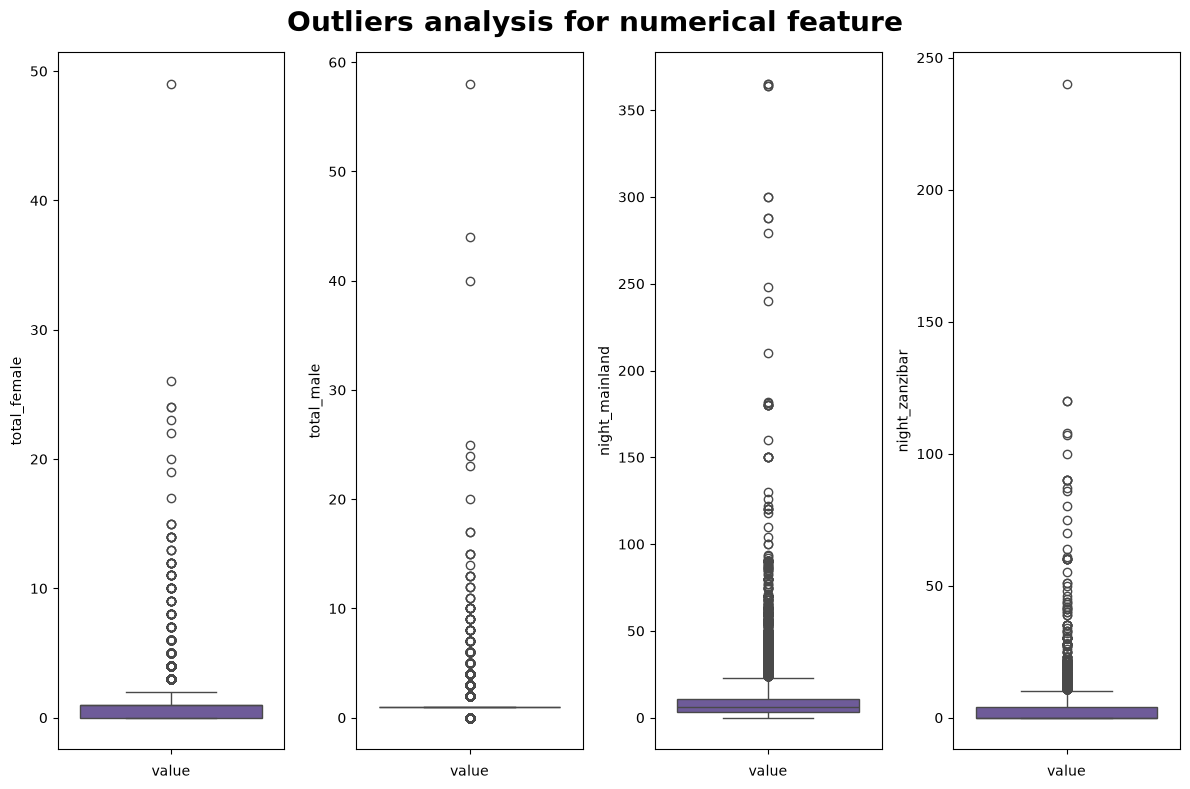

In [263]:
fig, axes = plt.subplots(1,4, figsize=(12,8))
for i, col in enumerate(NUMERIC_COLS):
    sns.boxplot(
        data=df,
        y=col,
        ax=axes[i],
        color="#6a51a3")
    axes[i].set_xlabel("value")
fig.suptitle("Outliers analysis for numerical feature",y=0.98,fontsize=20,fontweight='bold')
plt.tight_layout()


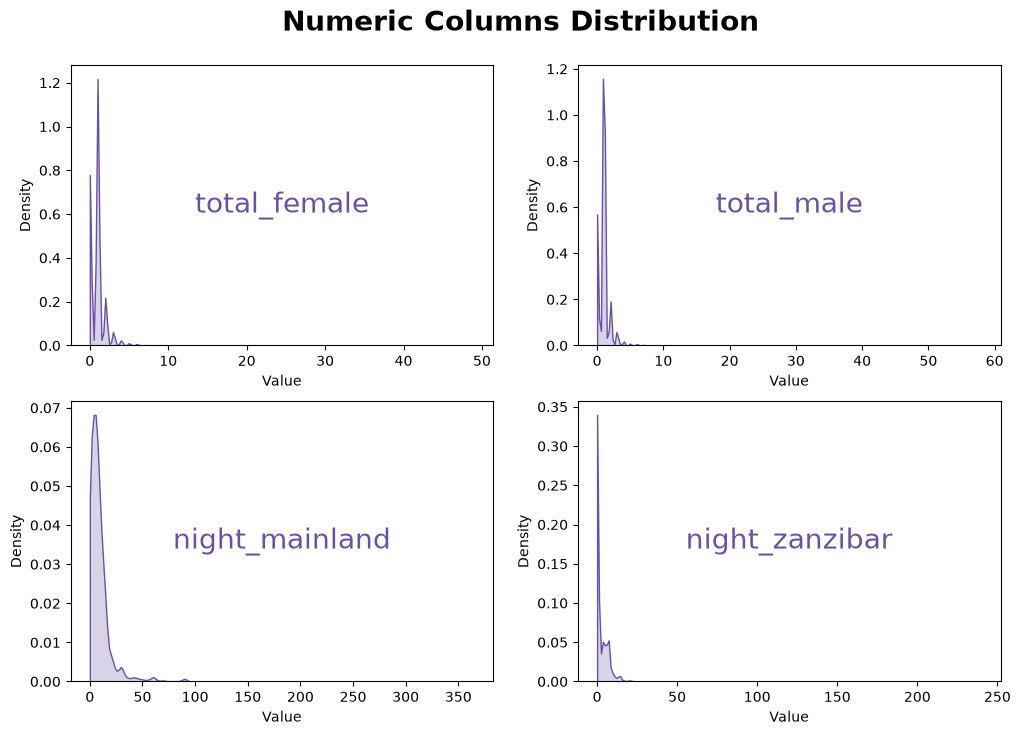

In [294]:
fig, axes = plt.subplots(2,2, figsize=(12,8),)
axes = axes.flatten()
for i, col in enumerate(NUMERIC_COLS):
    sns.kdeplot(
        data=df,
        x=col,
        ax=axes[i],
        clip=(df[col].min(), df[col].max()),
        color="#6a51a3",
        fill=True
        )
    axes[i].text(0.5,0.5,str(col),transform=axes[i].transAxes,ha="center",va="center",fontsize=20,color="#6a51a3")
    axes[i].set_xlabel("Value")
    fig.suptitle("Numeric Columns Distribution",y=0.95,fontsize=20,fontweight="bold")


### **What did we learn?**
- Most of the data is concentrated and compressed near zero.
  - `total_female` and `total_male` start from 0 to 4 people in normal range 
  - people spend days in mainland `night_mainland` more than zanzibar `night_zanzibar`
  - `night_mainland` value start from 0 to 20 days, in `night_zanzibar` start from 0 to 10 days
- The outliers occupy the higher values.
- There is severe `right-skewness` in the data.
- How to handle this data in the `data preprocessing` stages and `machine learning` algorithms:
  - The mean will be heavily affected by the severe skewness in the data, so we will not use it.
  - The best algorithms for this data are `tree-based models`.
  - It is preferable to apply a `logarithmic transformation` to this numerical data due to the severe skewness in the data.

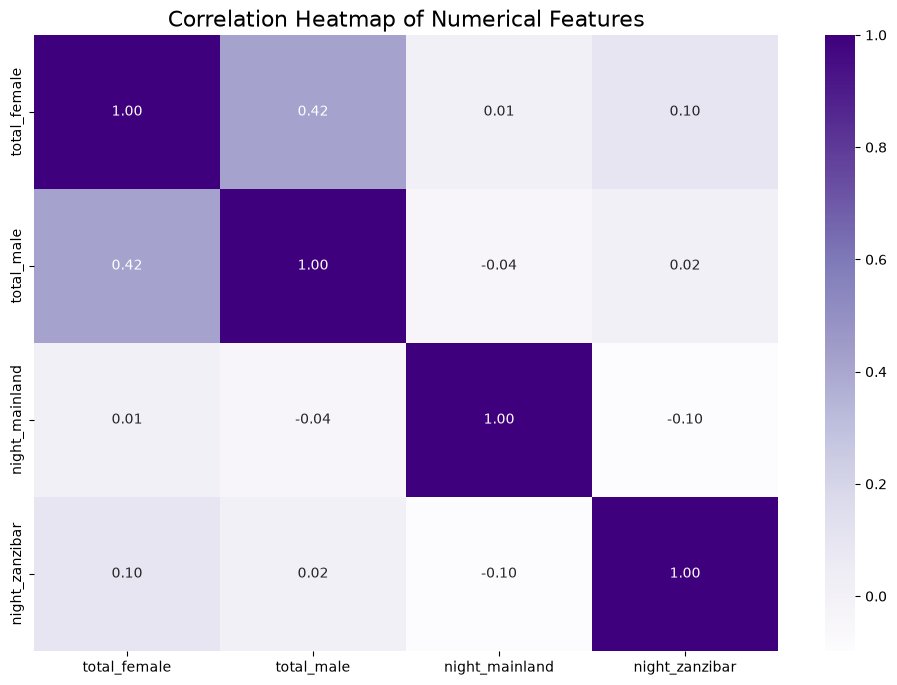

In [193]:
plt.figure(figsize=(12, 8))
sns.heatmap(df[NUMERIC_COLS].corr(), annot=True, cmap='Purples', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features', fontsize=16)
plt.show()


### **What did we learn?**
- Positive correlation ($r = 0.42$):
  - Between `total_female` and `total_male`
- Number of individuals can't affect the night spent in Mainland or Zanzibar city.


### **What should we do next?**
- Understand Categorical Feature and anlysis it.

## 7. Categorical Feature Analysis

Categorical variables are analyzed based on their frequency distributions.

This allows us to identify:

- Dominant categories.
- Rare categories.
- High-cardinality features.
- Potential data-entry inconsistencies.

In [26]:
df[CATEGORICAL_COLS]. describe().T
categorical_summary = pd.DataFrame({
    'null_count' : df[CATEGORICAL_COLS].count(),
    'isnull_count' : df[CATEGORICAL_COLS].isnull().sum(),
    'null_percentage' : (df[CATEGORICAL_COLS].isna().mean() * 100).round(2),
    'num_unique' : df[CATEGORICAL_COLS].nunique()
    }).replace(0, "")


categorical_summary

,null_count,isnull_count,null_percentage,num_unique
country,18506,,,131
age_group,18506,,,5
travel_with,17431,1075,5.81,5
first_trip_tz,18506,,,2
purpose,18506,,,8
main_activity,18506,,,10
info_source,18506,,,8
tour_arrangement,18506,,,2
package_transport_int,18506,,,2
package_accomodation,18506,,,2



country
UNITED STATES OF AMERICA    15.38
UNITED KINGDOM              11.46
ITALY                        8.78
FRANCE                       5.75
GERMANY                      5.24
                            ...  
BARBADOS                     0.01
DJIBOUT                      0.01
TUNISIA                      0.01
MONTENEGRO                   0.01
JORDAN                       0.01
Name: count, Length: 131, dtype: float64
Axes(0.125,0.11;0.775x0.77)
Axes(0.125,0.11;0.775x0.77)


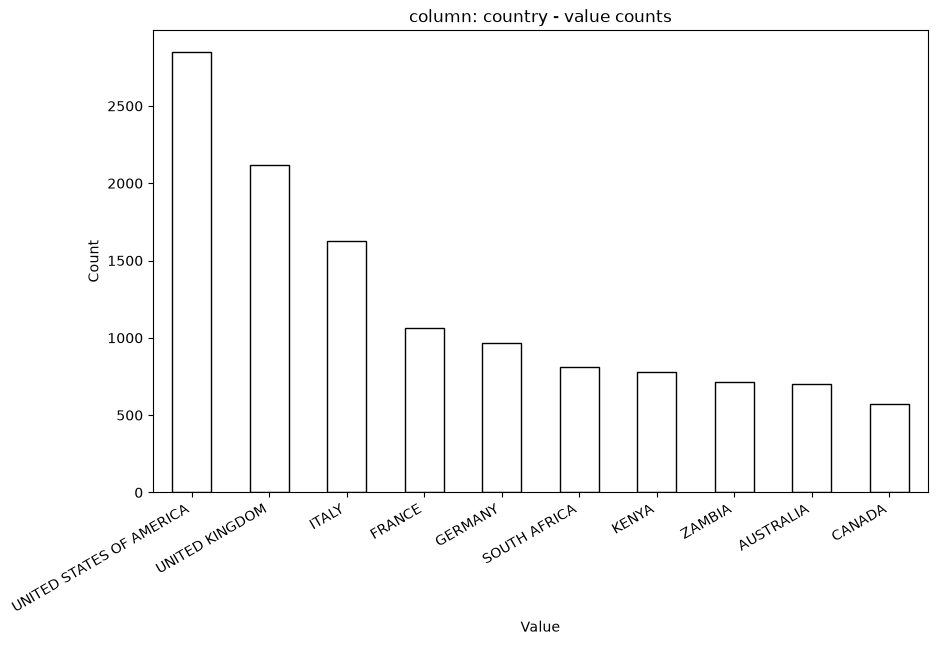

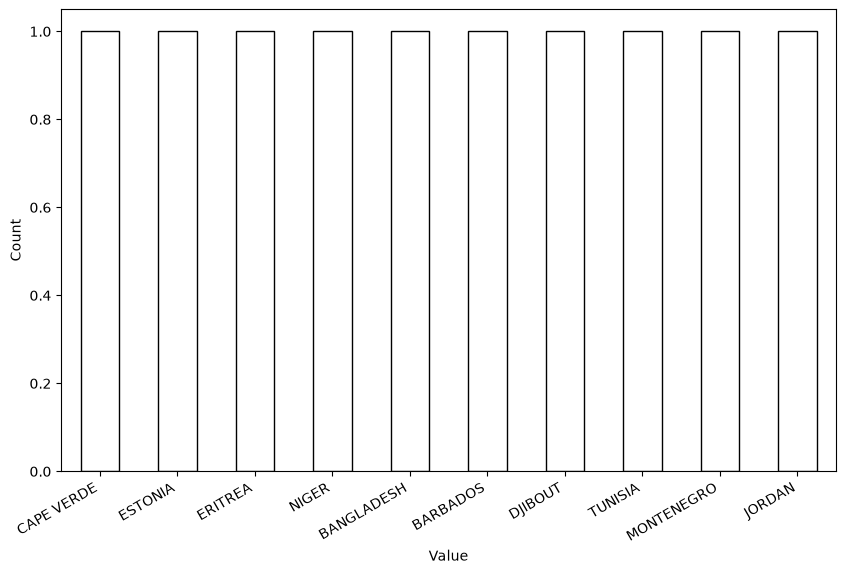


age_group
25-44    48.89
45-64    30.52
18-24    12.01
65+       7.93
<18       0.66
Name: count, dtype: float64


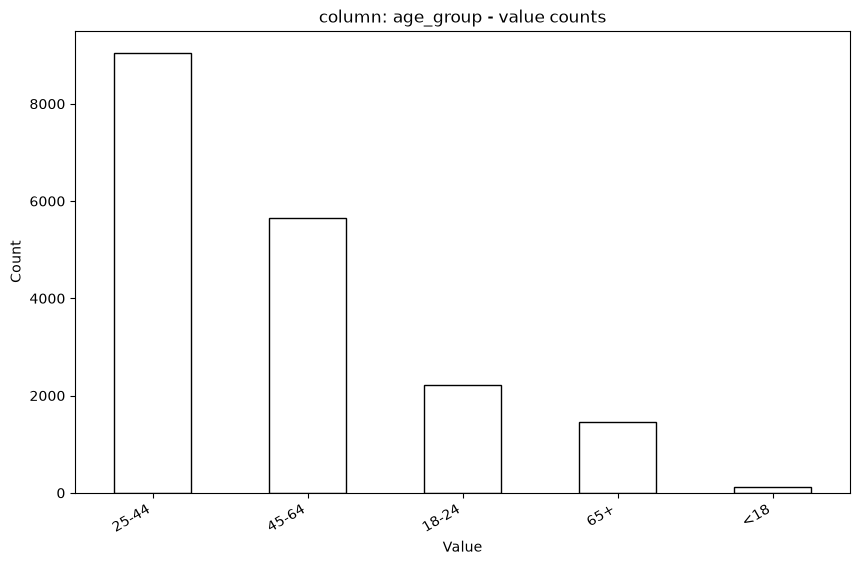


travel_with
Alone                           43.54
With Spouse                     27.78
With Other Friends/Relatives    18.75
With Spouse and Children         6.84
With Children                    3.09
Name: count, dtype: float64


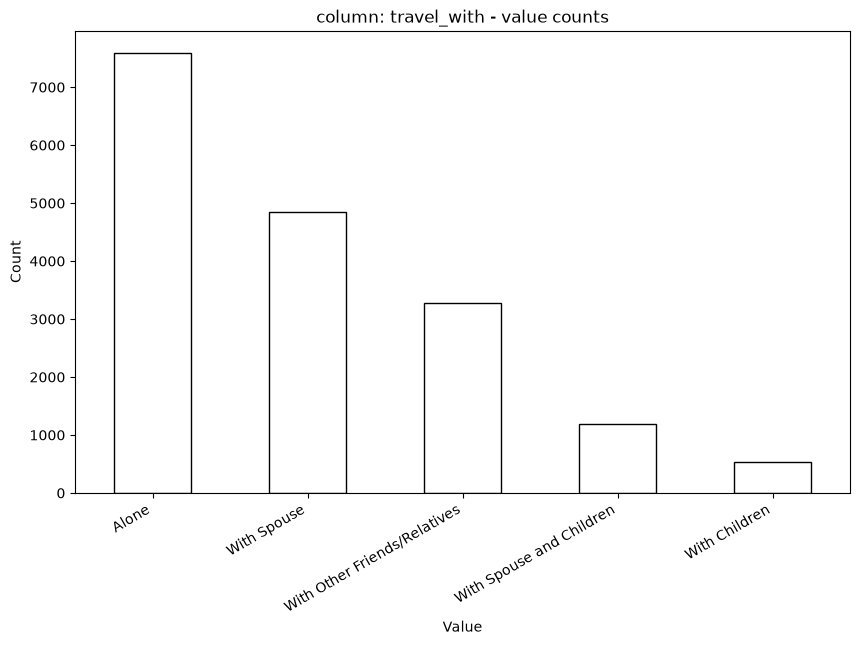


first_trip_tz
Yes    68.83
No     31.17
Name: count, dtype: float64


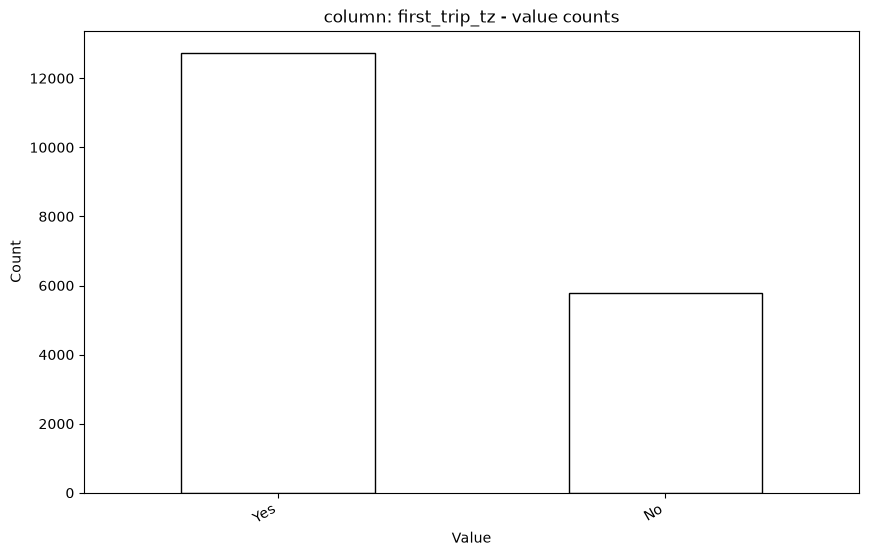


purpose
Leisure and Holidays              63.52
Visiting Friends and Relatives    12.45
Business                          12.41
Meetings and Conference            6.37
Volunteering                       2.37
Other                              1.76
Scientific and Academic            1.07
Medical                            0.05
Name: count, dtype: float64


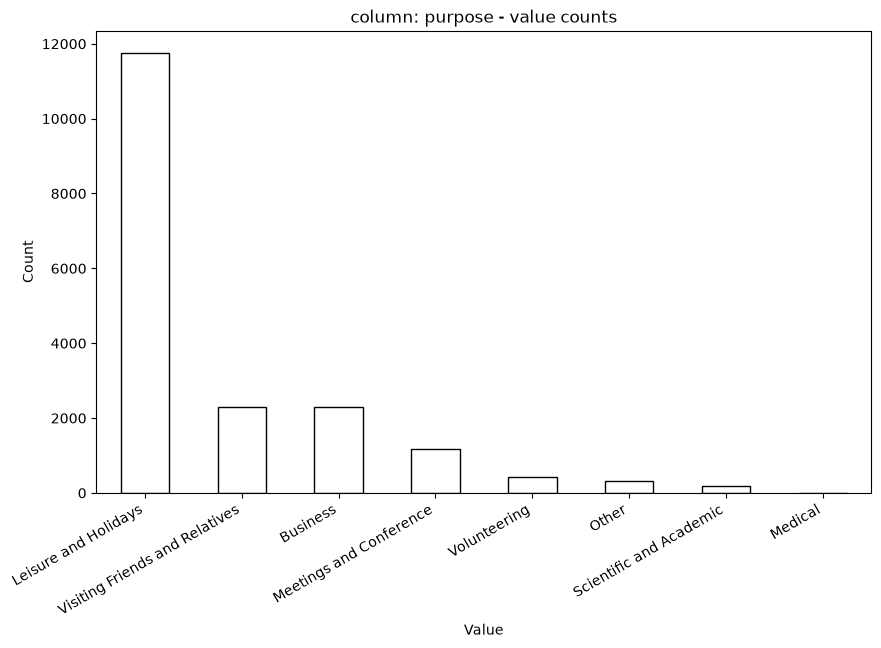


main_activity
Widlife Tourism             32.36
Beach Tourism               22.54
Wildlife Tourism            12.34
Conference Tourism          10.38
Hunting Tourism              9.25
Cultural Tourism             7.80
Mountain Climbing            2.86
Business                     1.51
Bird Tourism                 0.78
Diving and Sport Fishing     0.18
Name: count, dtype: float64


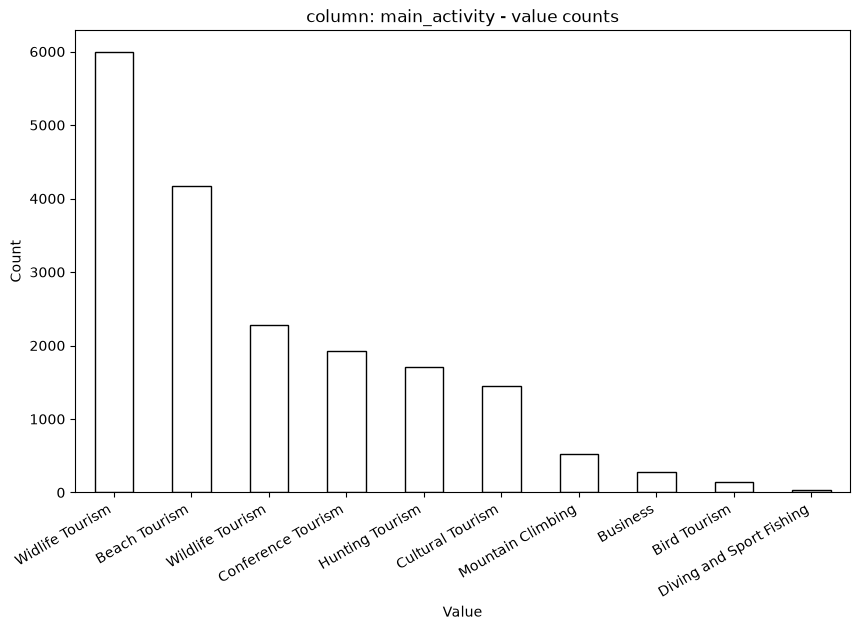


info_source
Travel agent, tour operator        43.26
Friends, relatives                 32.84
Others                              7.39
Newspaper, magazines, brochures     7.03
Radio, TV, Web                      6.61
Trade fair                          1.31
Tanzania Mission Abroad             1.06
Inflight magazines                  0.50
Name: count, dtype: float64


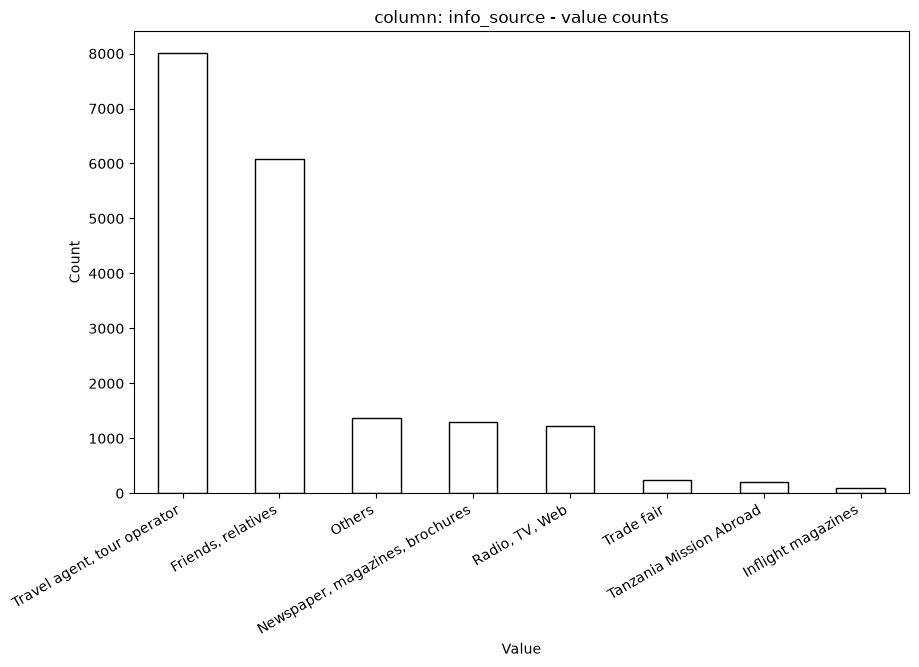


tour_arrangement
Package Tour    50.23
Independent     49.77
Name: count, dtype: float64


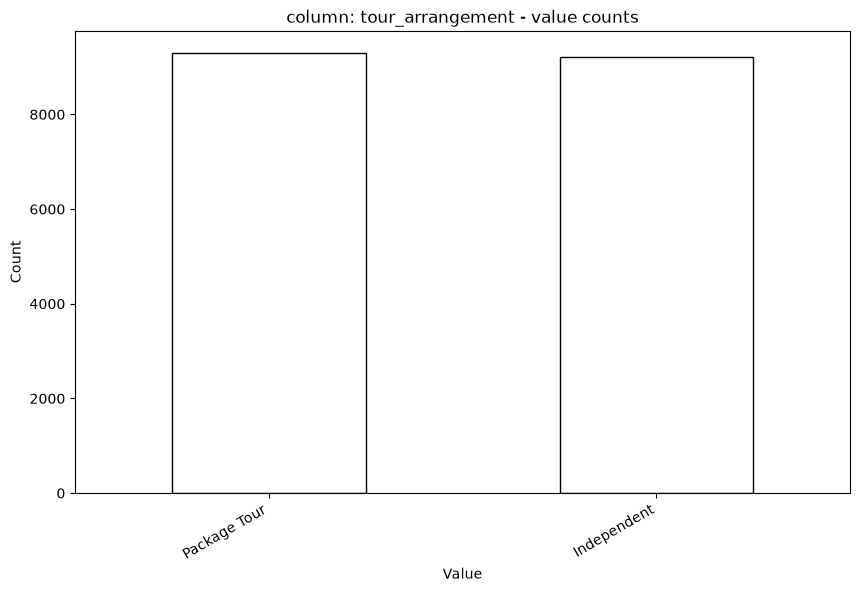


package_transport_int
No     66.13
Yes    33.87
Name: count, dtype: float64


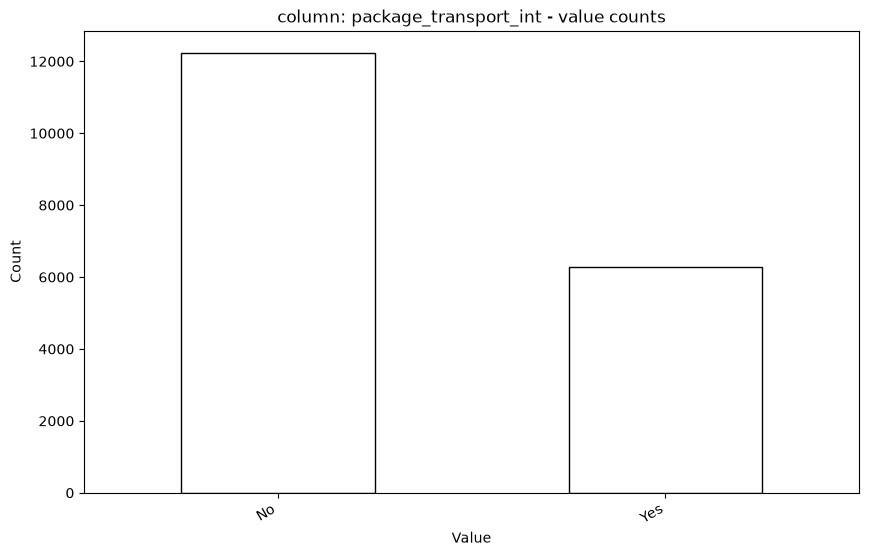


package_accomodation
No     51.56
Yes    48.44
Name: count, dtype: float64


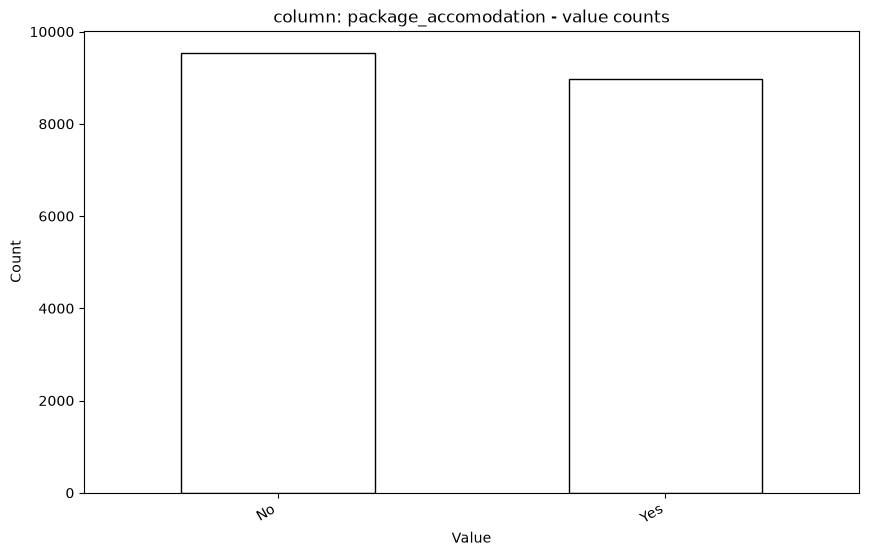


package_food
No     54.81
Yes    45.19
Name: count, dtype: float64


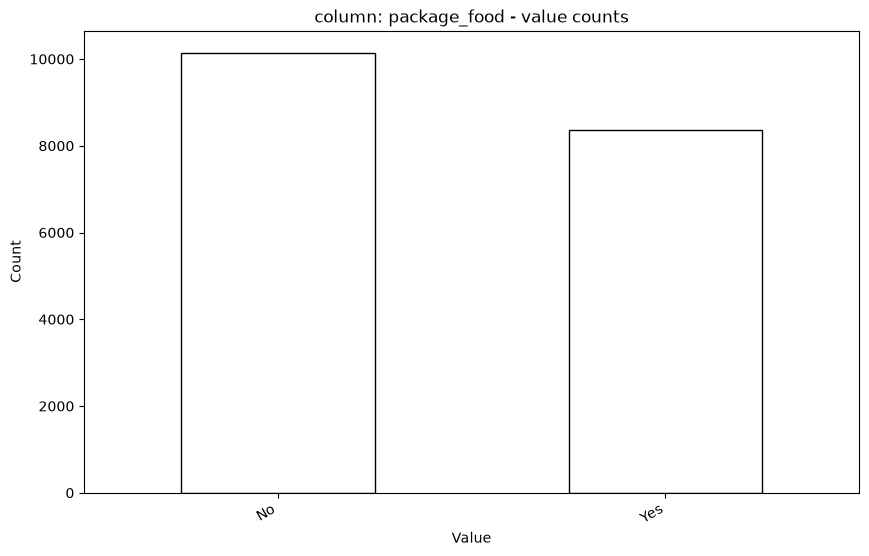


package_transport_tz
No     58.75
Yes    41.25
Name: count, dtype: float64


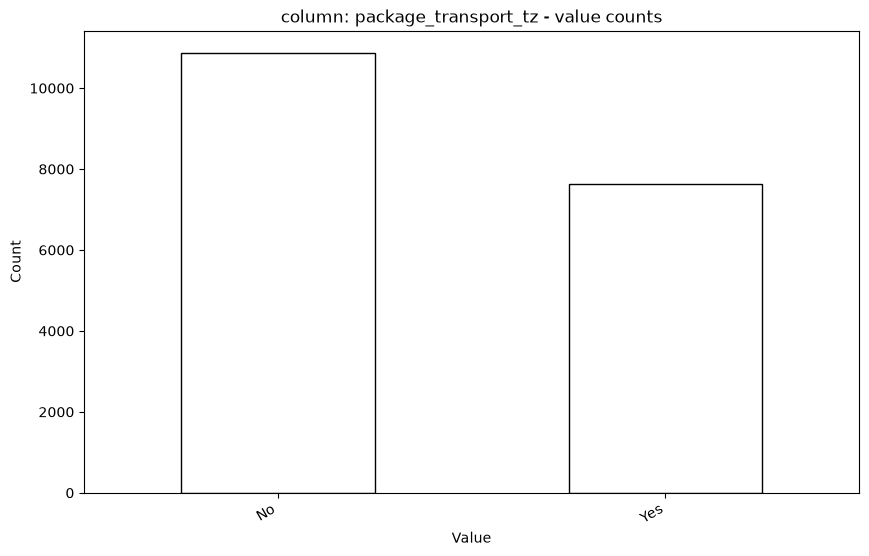


package_sightseeing
No     69.09
Yes    30.91
Name: count, dtype: float64


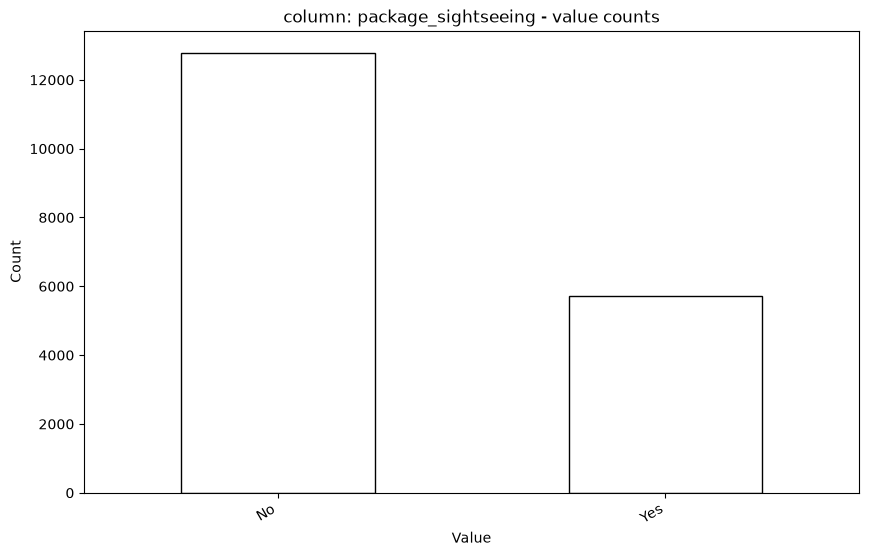


package_guided_tour
No     67.26
Yes    32.74
Name: count, dtype: float64


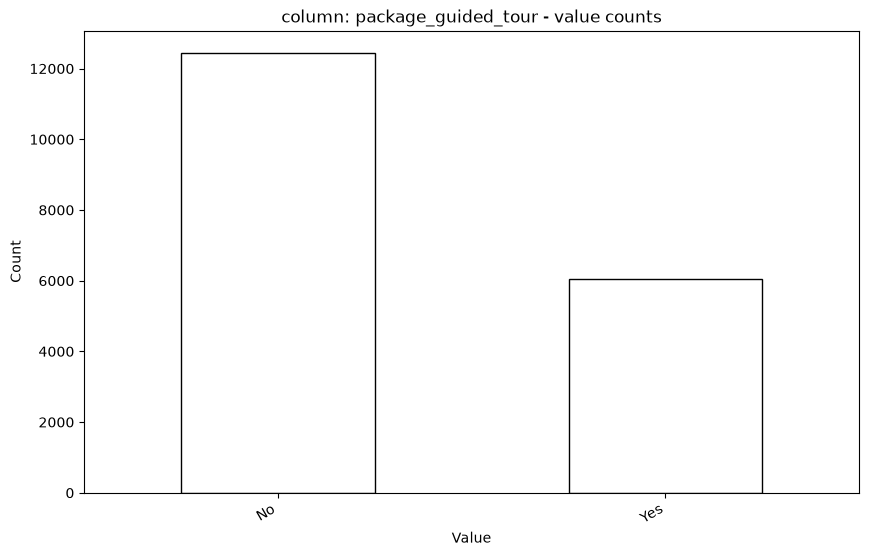


package_insurance
No     85.43
Yes    14.57
Name: count, dtype: float64


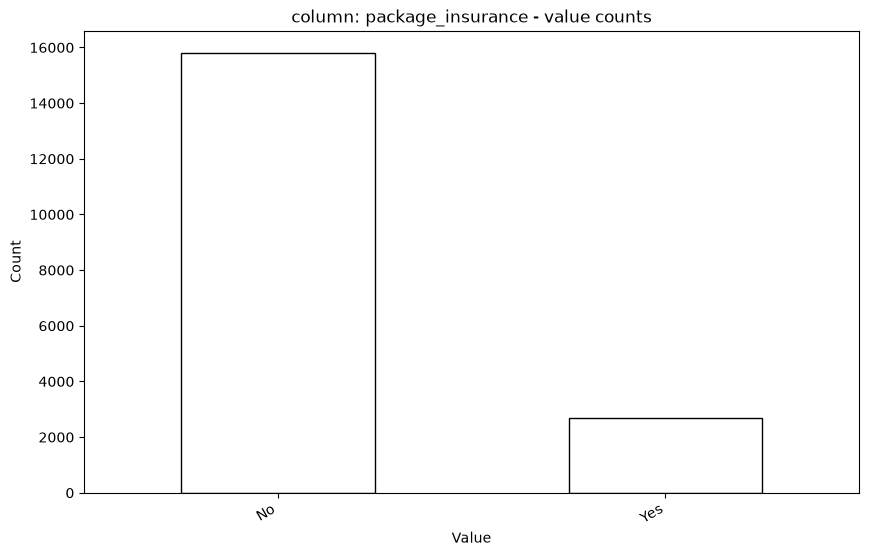

In [298]:
def value_per(df, column):
    total_count = df[column].count()
    value_counts = df[column].value_counts()
    percentage = value_counts / total_count * 100
    print (percentage.round(2))

for col in CATEGORICAL_COLS:
    print(f'')
    value_per(df, col)

    plt.figure(figsize=(10,6))
    plt.title(f'column: {col} - value counts')
    
    if col == 'country':
        print(df[col].value_counts().head(10).plot(kind='bar', color='white', edgecolor='black'))
        plt.xticks(rotation=30, ha='right')
        plt.xlabel('Value')
        plt.ylabel('Count')
        
        plt.figure(figsize=(10,6))
        print(df[col].value_counts().tail(10).plot(kind='bar', color='white', edgecolor='black'))

    else:
        df[col].value_counts().plot(kind='bar', color='white', edgecolor='black')
    plt.xticks(rotation=30, ha='right')
    plt.xlabel('Value')
    plt.ylabel('Count')
    plt.show()

### **What did we learn?**

- top 3 `country` of vistor :
  - `UNITED STATES OF AMERICA` with 15.38% 
  - `UNITED KINGDOM` with 11.46% 
  - `ITALY` with 8.78%
- `age_group` : 
  - age group class `25-44` equal 48.89% of age group class `45-64` is 30.52%,
  - class `18-24` is 12.01%, `65+` is 7.93%  and `<18`is 0.66%
- `travel_with` records :
  - Alone `43.54%`,
  - With Spouse `27.78%`, With Other Friends/Relatives `18.75%`.
  - With Spouse and Children `6.84%`, With Children `3.09%`. 
- top 3 `purpose` :
  - Leisure and Holidays `63.52%`
  - Visiting Friends and Relatives `12.45%`
  - Business `12.41%`
- top 3 `main_activity` :
  - Widlife Tourism `32.36%`
  - Beach Tourism `22.54%`
  - Wildlife Tourism `12.34%`
- top `info_source` :
  - Travel agent, tour operator `43.26%`
  - Friends, relatives `32.84%`

### **What should we do next?**
- Understand and analysis `Target` column.

## 8. Target Variable Analysis

The target variable is `cost_category`.

Before training any model, it is important to understand the distribution of the target classes.

This analysis helps determine whether the dataset suffers from class imbalance and whether additional strategies may be required during model training.

In [28]:
print('\n Target column shape: ', df[TARGET_COL].shape,'\n')

print('Target column info: ')
df[TARGET_COL].info()

print('\nTarget column value percentage:')
value_per(df, TARGET_COL)



 Target column shape:  (18506,) 

Target column info: 
<class 'pandas.core.series.Series'>
RangeIndex: 18506 entries, 0 to 18505
Series name: cost_category
Non-Null Count  Dtype 
--------------  ----- 
18506 non-null  object
dtypes: object(1)
memory usage: 144.7+ KB

Target column value percentage:
cost_category
Normal Cost     29.56
Higher Cost     26.29
High Cost       19.87
Lower Cost      13.87
Low Cost         8.46
Highest Cost     1.94
Name: count, dtype: float64


(array([0, 1, 2, 3, 4, 5]),
 [Text(0, 0, 'Lower Cost'),
  Text(1, 0, 'Low Cost'),
  Text(2, 0, 'Normal Cost'),
  Text(3, 0, 'High Cost'),
  Text(4, 0, 'Higher Cost'),
  Text(5, 0, 'Highest Cost')])

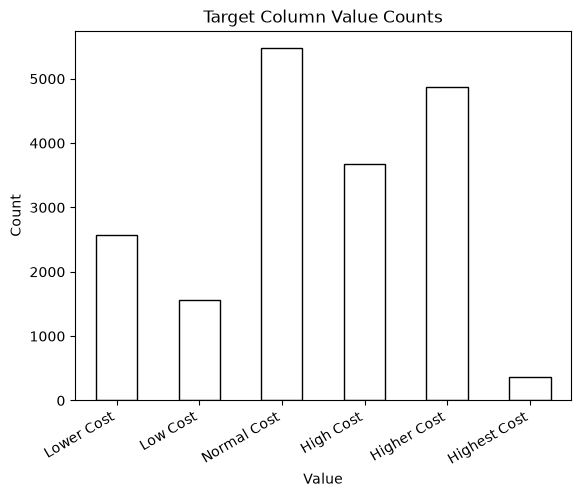

In [29]:
df[TARGET_COL].value_counts().reindex(TARGET_CLASSES).plot(kind='bar', color='white', edgecolor='black', title='Target Column Value Counts', xlabel='Value', ylabel='Count') 
plt.xticks(rotation=30, ha='right')

In [30]:

counts = df[TARGET_COL].value_counts()
max_to_min_ratio = counts.max() / counts.min()
print(f"Imbalance Ratio (Max/Min): {max_to_min_ratio:.2f}x")


Imbalance Ratio (Max/Min): 15.24x


### **What did we learn?**
- `cost_category` column have 18,506 complete records, without any missing values.
- 6 class in `cost_category` column :
  - `Normal Cost` (29.56%) represents the `largest` category of visitors to the country.
  - `Higher Cost` (26.29%) and `High Cost` (19.87%) account for approximately `half of the visitors`.
  - `Lower Cost` (13.87%) and Low Cost (8.46%) account for less than a `quarter of the country's visitors`.
  - `Highest Cost` (1.94%) is the least frequent category visiting the country.
- Since there is a very minority class representing `1.94%`, this class must be distributed in a balanced manner during data splitting in the `machine learning stage`.
- Standard accuracy in the evaluation phase will not be a fair metric due to the presence of minority classes representing `1.94%`, so a better metric must be chosen that is not affected by `class imbalance`.
- Search for algorithms/techniques to address `class imbalance` in certain categories of the target column.

### **What should we do next?**
- Understand Correlation analysis

## 9. Correlation Analysis

Correlation analysis is used to examine linear relationships between numerical variables.

The purpose is not to automatically remove highly correlated features, but to identify potential relationships, redundancy, and patterns that may require further investigation.

<Axes: >

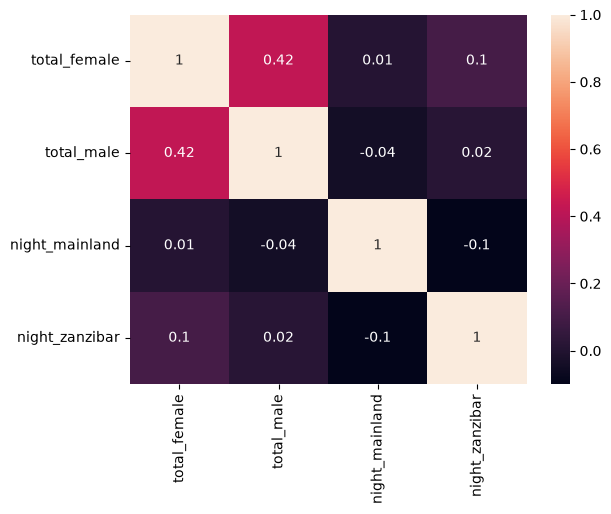

In [284]:
sns.heatmap(df[NUMERIC_COLS].corr().round(2),annot=True)

#### note: as you see in last figur have a less data about numeric columns
#### so i need to lock to use Categorical Association Matrix to see more data 

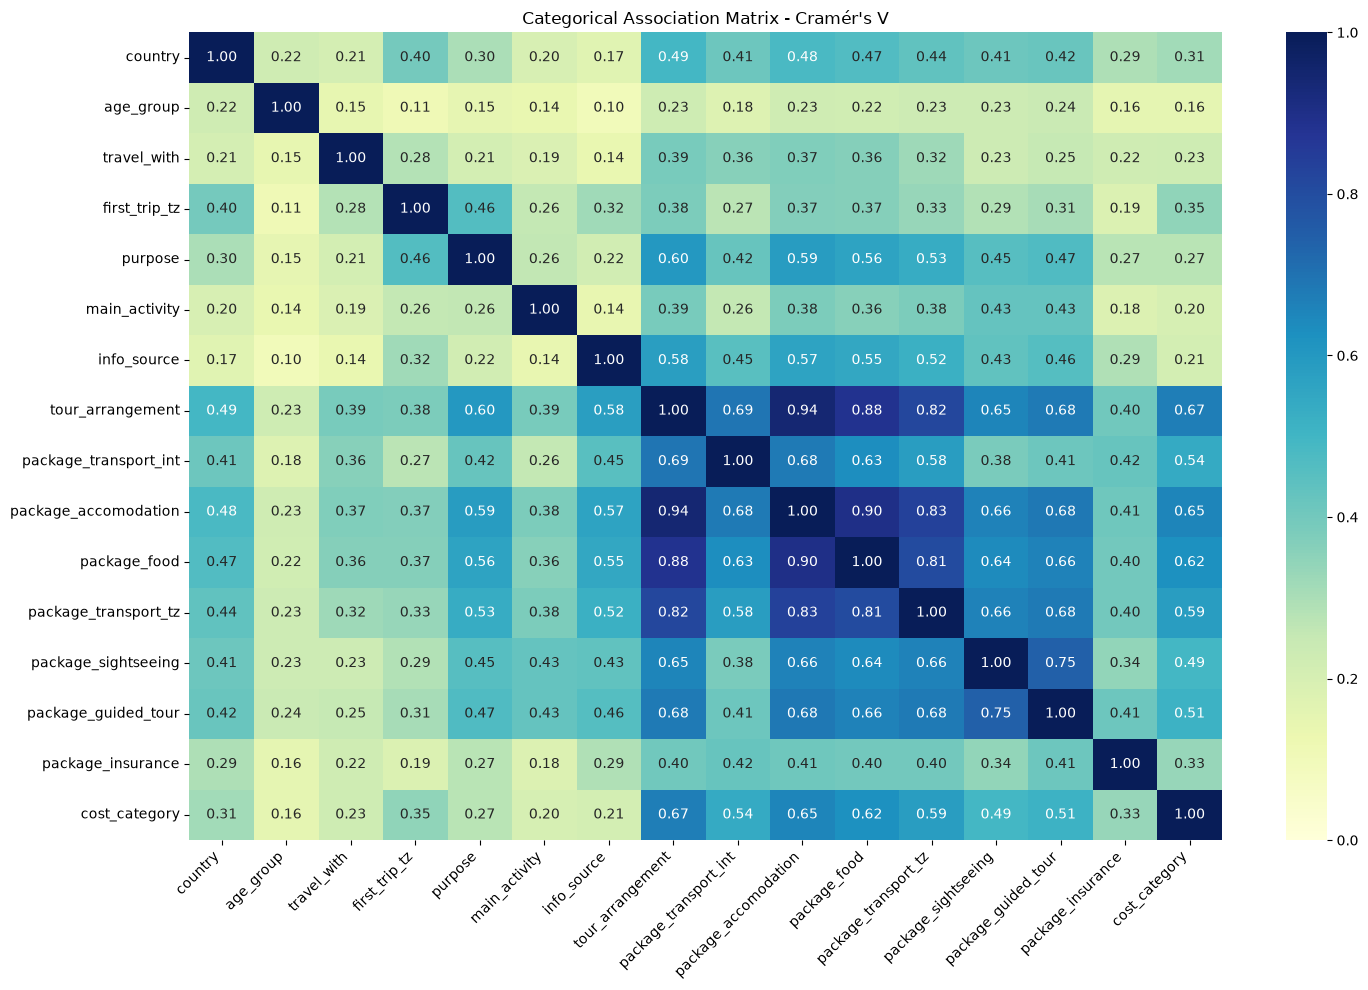

In [282]:


result = associations(df[CATEGORICAL_COLS + [TARGET_COL]], nominal_columns='all', compute_only=True, plot=False)

cramers_matrix = result['corr']

plt.figure(figsize=(15, 10))
sns.heatmap(cramers_matrix, annot=True, cmap='YlGnBu',fmt='.2f', vmin=0, vmax=1)
plt.title("Categorical Association Matrix - Cramér's V")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### **What did we learn?**
- strongly associated correlation with target column `cost_category` :
  - tour_arrangement 0.67, package_accommodation 0.67, package_food 0.62, package_transport_tz 0.59, package_transport_int 0.54, package_guided_tour 0.51, package_sightseeing 0.49 
- The package-related features are strongly associated with one another, and target column `cost_category`.

### **What should we do next?**
- Outlier Analysis 

## **10. Outlier Analysis**

Outliers are observations that differ substantially from the majority of the data.

They may represent:

- Genuine extreme observations.
- Data-entry errors.
- Measurement errors.
- Rare but meaningful cases.

Therefore, outliers will not be removed automatically. Each relevant feature will be investigated before applying any treatment.

total_female | outliers : 946 - 5.11%
total_male | outliers : 6692 - 36.16%
night_mainland | outliers : 1148 - 6.20%
night_zanzibar | outliers : 729 - 3.94%


Text(0.5, 1.0, 'Boxplot for numeric columns')

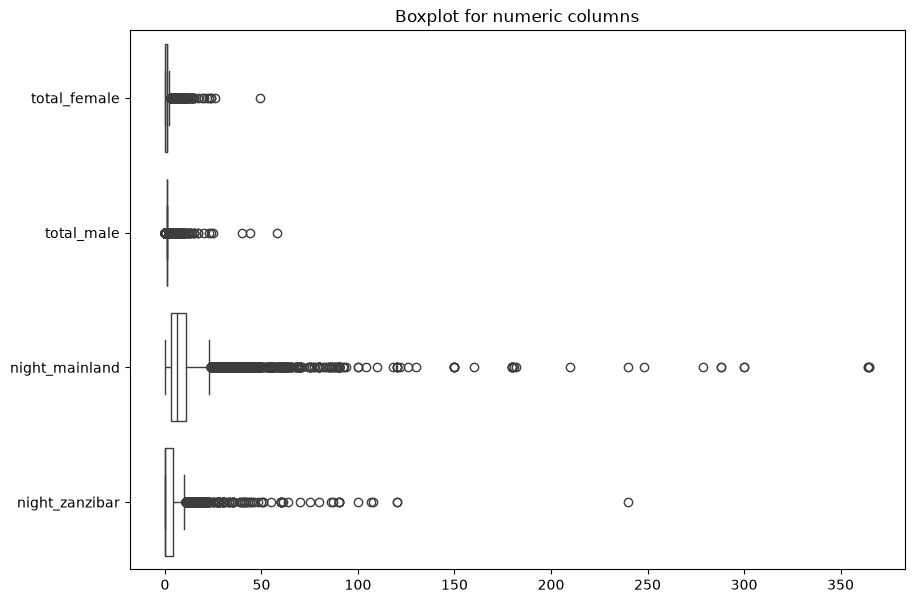

In [299]:
for col in NUMERIC_COLS:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1 
    lower_b = Q1 - 1.5 * IQR
    upper_b = Q3 + 1.5 * IQR

    outliers_count = df[(df[col] < lower_b) | (df[col] > upper_b)][col].count()
    count_per = outliers_count / len(df) * 100

    print(f"{col} | outliers : {outliers_count} - {count_per:.2f}%")


plt.figure(figsize=(10,7))
sns.boxplot(data=df[NUMERIC_COLS], orient='h', color='white')
plt.title('Boxplot for numeric columns')


### **What did we learn?**

- More than a third of the samples in `total_male` are outliers.
  - `total_male` outliers : 6692 - `36.16%`

- The outlier percentages for the remaining features are within normal limits.
  - `total_female` outliers : 946 - `5.11%`
  - `night_mainland` outliers : 1148 - `6.20%`
  - `night_zanzibar` outliers : 729 - `3.94%`

- in data processing stage :  
  - We will remove the most extreme values, while the outliers that appear in groups will not be removed.

### **What should we do next?**
- Write EDA Summary


## **11. EDA Summary**

### **1. Dataset Overview & Structure**
- The dataset included `18,506` and 21 columns (1 ID column, 19 features, and 1 classification target)
- data types in dataset is `int64` (2 columns), `float64` (2 columns), and `object` (16 columns).
- The dataset includes `4` numerical features, `15` categorical features, and `1` classification target.
- Missing data : `1,075` missing values in `travel_with`, `2` in `total_female`, and `6` in `total_male`.
- no duplicates rows.

### **2. Numerical Features & Outliers**
- Numerical features is `total_female`, `total_male`, `night_mainland`, and `night_zanzibar` with high right-skewness. 
- The IQR is concentrated near zero. 
- High percentage of outliers in `total_male` with 36.16%, and low percentages in `total_female` (5.11%), `night_mainland` (6.20%), and `night_zanzibar` (3.94%).

### **3. Bivariate Association Analysis**
- strongly associated correlation with target column `cost_category` :
  - tour_arrangement 0.67, package_accommodation 0.67, package_food 0.62, package_transport_tz 0.59, package_transport_int 0.54, package_guided_tour 0.51, package_sightseeing 0.49 
- The package-related features are strongly associated with one another, and target column `cost_category`.

### **4. Target Variable Analysis**
- `cost_category` column have 18,506 complete records, without any missing values.
- 6 class in `cost_category` column :
  - `Normal Cost` (29.56%) represents the `largest` category of visitors to the country.
  - `Higher Cost` (26.29%) and `High Cost` (19.87%) account for approximately `half of the visitors`.
  - `Lower Cost` (13.87%) and Low Cost (8.46%) account for less than a `quarter of the country's visitors`.
  - `Highest Cost` (1.94%) is the least frequent category visiting the country.
- Since there is a very minority class representing `1.94%`, this class must be distributed in a balanced manner during data splitting in the `machine learning stage`.
- Standard accuracy in the evaluation phase will not be a fair metric due to the presence of minority classes representing `1.94%`, so a better metric must be chosen that is not affected by `class imbalance`.
- Search for algorithms/techniques to address `class imbalance` in certain categories of the target column.

### **5. Next Steps**

- **Missing Values:**: Handle missing values.
- **Data Quality:**: Investigate and resolve data quality issues identified during exploratory data analysis.
- **Outlier Investigation:**: Handle outliers using appropriate techniques.
- **Data Validation**: Verify data validity, data types, and structural consistency across the training and test datasets.
- **Next Stage**: Proceed to `02_data_preprocessing.ipynb` 